In [9]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [11]:
DATA_PATH = "data/creditcard.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Check that creditcard.csv is inside the data folder."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [12]:
print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset dimensions:
(284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  floa

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [13]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nOriginal class distribution:")
print(df["Class"].value_counts())

Missing values: 0
Duplicate rows: 1081

Original class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [14]:
rows_before = len(df)

df = df.drop_duplicates().copy()

rows_after = len(df)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)
print("Remaining duplicates:", df.duplicated().sum())

print("\nClass distribution after cleaning:")
print(df["Class"].value_counts())

Rows before: 284807
Rows after: 283726
Rows removed: 1081
Remaining duplicates: 0

Class distribution after cleaning:
Class
0    283253
1       473
Name: count, dtype: int64


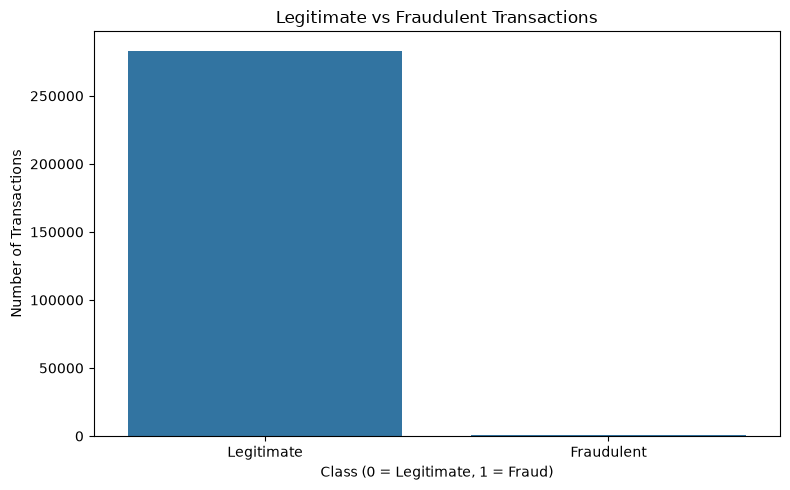

Legitimate transactions: 283253
Fraudulent transactions: 473
Fraud percentage: 0.1667 %


In [15]:
class_counts = df["Class"].value_counts().reindex([0, 1], fill_value=0)

plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.tight_layout()
plt.show()

print("Legitimate transactions:", int(class_counts[0]))
print("Fraudulent transactions:", int(class_counts[1]))
print("Fraud percentage:", round(df["Class"].mean() * 100, 4), "%")

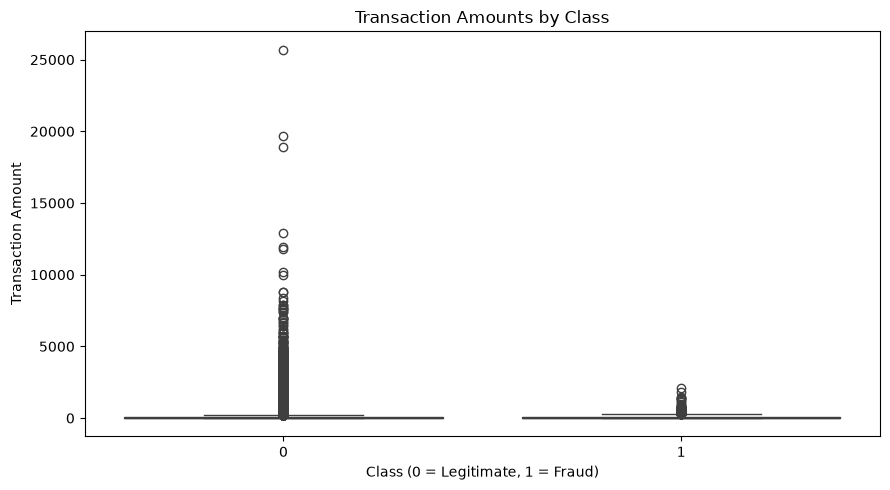

In [16]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.title("Transaction Amounts by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.tight_layout()
plt.show()

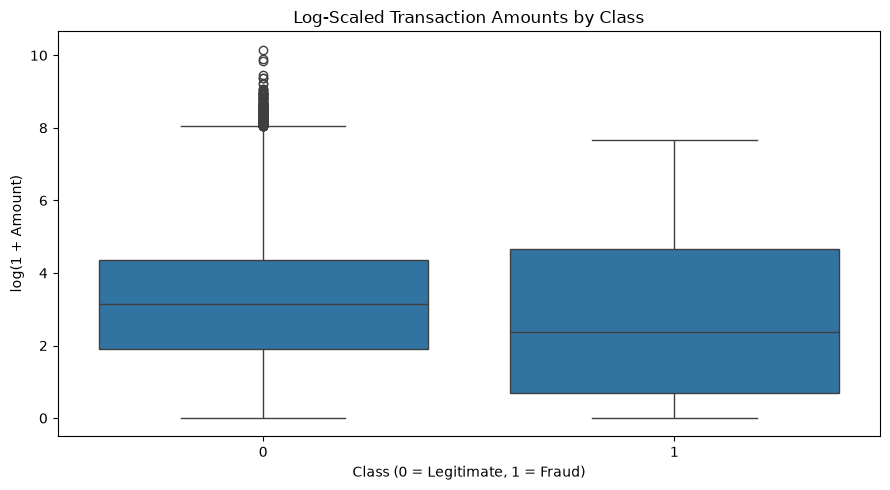

In [17]:
df["Amount_log"] = np.log1p(df["Amount"])

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Class", y="Amount_log")

plt.title("Log-Scaled Transaction Amounts by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

Five most negatively correlated features:


V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dtype: float64

Five most positively correlated features:


V8     0.033068
V19    0.033631
V2     0.084624
V4     0.129326
V11    0.149067
Name: Class, dtype: float64

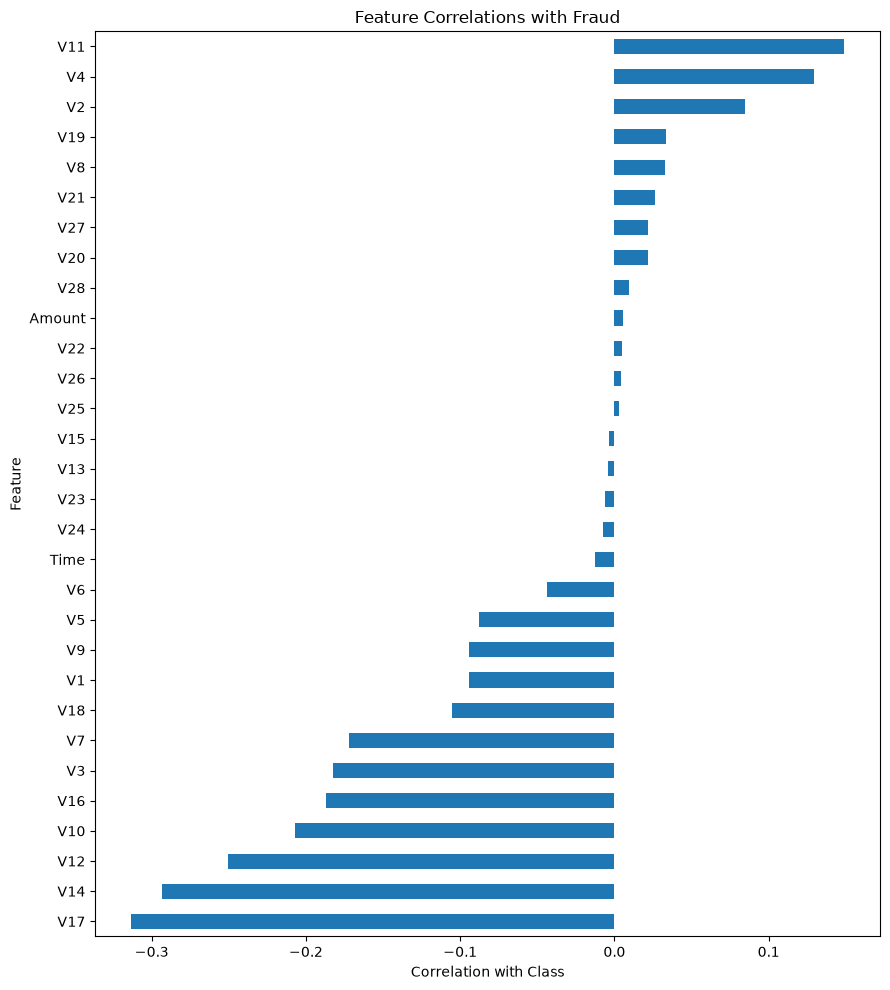

In [18]:
correlations = (
    df.drop(columns=["Amount_log"], errors="ignore")
      .corr(numeric_only=True)["Class"]
      .drop("Class")
      .sort_values()
)

print("Five most negatively correlated features:")
display(correlations.head(5))

print("Five most positively correlated features:")
display(correlations.tail(5))

plt.figure(figsize=(9, 10))
correlations.plot(kind="barh")

plt.title("Feature Correlations with Fraud")
plt.xlabel("Correlation with Class")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [19]:
X = df.drop(columns=["Class", "Amount_log"], errors="ignore")
y = df["Class"].astype(int)

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

Input features shape: (283726, 30)
Target shape: (283726,)
Number of features: 30
Target classes: [np.int64(0), np.int64(1)]


In [20]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nFraud cases in each set:")
print("Training:", int(y_train.sum()))
print("Validation:", int(y_val.sum()))
print("Test:", int(y_test.sum()))

print("\nSplit percentages:")
print("Training:", round(len(X_train) / len(X) * 100, 2), "%")
print("Validation:", round(len(X_val) / len(X) * 100, 2), "%")
print("Test:", round(len(X_test) / len(X) * 100, 2), "%")

Training set: (198608, 30)
Validation set: (42559, 30)
Test set: (42559, 30)

Fraud cases in each set:
Training: 331
Validation: 71
Test: 71

Split percentages:
Training: 70.0 %
Validation: 15.0 %
Test: 15.0 %


In [21]:
def evaluate_model(model, X_data, y_true, model_name):
    y_pred = model.predict(X_data)
    y_prob = model.predict_proba(X_data)[:, 1]

    results = {
        "Model": model_name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "Average Precision": average_precision_score(y_true, y_prob)
    }

    print(f"\n{model_name} — Classification Report")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

    print("Confusion matrix:")
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraud"]
    )
    display.plot(values_format="d")
    plt.title(f"{model_name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return results

In [22]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

start_time = time.time()

lr_model.fit(X_train, y_train)

lr_training_time = time.time() - start_time

print("Logistic Regression trained successfully!")
print("Training time:", round(lr_training_time, 2), "seconds")

Logistic Regression trained successfully!
Training time: 1.72 seconds



Logistic Regression — Classification Report
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     42488
       Fraud       0.05      0.89      0.10        71

    accuracy                           0.97     42559
   macro avg       0.53      0.93      0.54     42559
weighted avg       1.00      0.97      0.98     42559

Confusion matrix:
[[41308  1180]
 [    8    63]]


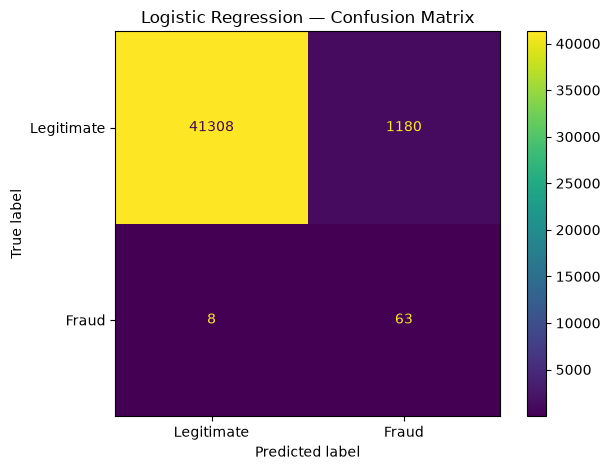


Validation metrics:


,Model,Precision,Recall,F1-score,Average Precision
0,Logistic Regression,0.0507,0.8873,0.0959,0.6971


In [23]:
lr_results = evaluate_model(
    lr_model,
    X_val,
    y_val,
    "Logistic Regression"
)

print("\nValidation metrics:")
display(pd.DataFrame([lr_results]).round(4))

In [24]:
rf_model = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print("Random Forest trained successfully!")
print("Training time:", round(rf_training_time, 2), "seconds")

Random Forest trained successfully!
Training time: 39.54 seconds



Random Forest — Classification Report
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42488
       Fraud       1.00      0.69      0.82        71

    accuracy                           1.00     42559
   macro avg       1.00      0.85      0.91     42559
weighted avg       1.00      1.00      1.00     42559

Confusion matrix:
[[42488     0]
 [   22    49]]


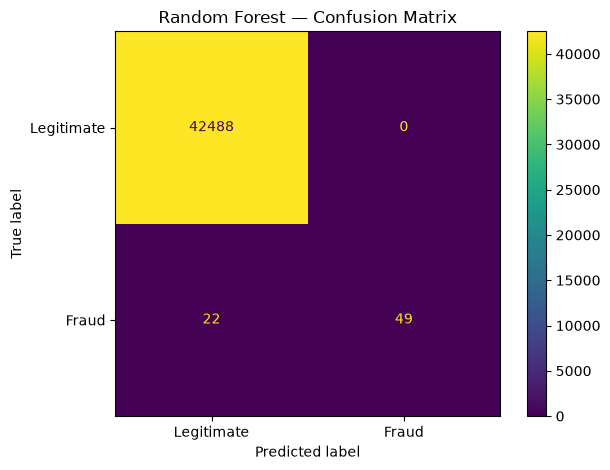


Validation metrics:


,Model,Precision,Recall,F1-score,Average Precision
0,Random Forest,1.0,0.6901,0.8167,0.8437


In [25]:
rf_results = evaluate_model(
    rf_model,
    X_val,
    y_val,
    "Random Forest"
)

print("\nValidation metrics:")
display(pd.DataFrame([rf_results]).round(4))

,Model,Precision,Recall,F1-score,Average Precision
0,Random Forest,1.0000,0.6901,0.8167,0.8437
1,Logistic Regression,0.0507,0.8873,0.0959,0.6971


<Figure size 900x500 with 0 Axes>

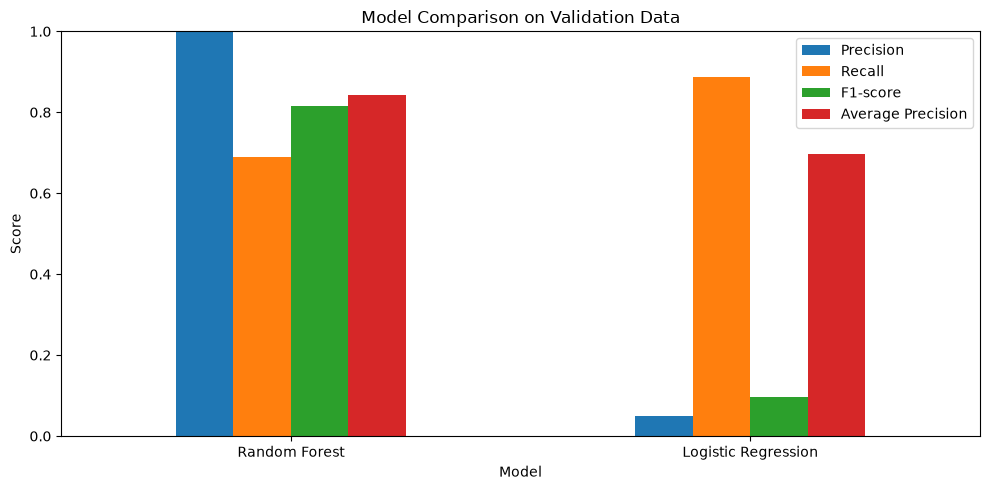

In [26]:
comparison = pd.DataFrame([
    lr_results,
    rf_results
])

comparison = comparison.sort_values(
    by="Average Precision",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

plt.figure(figsize=(9, 5))

comparison.set_index("Model")[
    ["Precision", "Recall", "F1-score", "Average Precision"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Model Comparison on Validation Data")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

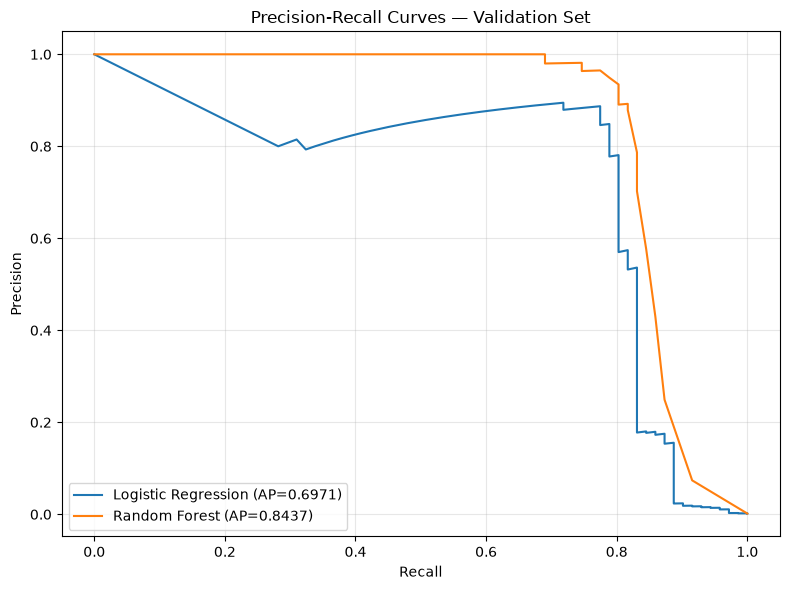

In [27]:
lr_probabilities = lr_model.predict_proba(X_val)[:, 1]
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

lr_precision, lr_recall, _ = precision_recall_curve(
    y_val, lr_probabilities
)

rf_precision, rf_recall, _ = precision_recall_curve(
    y_val, rf_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    lr_recall,
    lr_precision,
    label=f"Logistic Regression (AP={lr_results['Average Precision']:.4f})"
)

plt.plot(
    rf_recall,
    rf_precision,
    label=f"Random Forest (AP={rf_results['Average Precision']:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Validation Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
if rf_results["Average Precision"] >= lr_results["Average Precision"]:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print("Selected model:", best_model_name)
print("Selection based on validation Average Precision.")

Selected model: Random Forest
Selection based on validation Average Precision.



Random Forest — Final Test — Classification Report
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42488
       Fraud       0.93      0.73      0.82        71

    accuracy                           1.00     42559
   macro avg       0.96      0.87      0.91     42559
weighted avg       1.00      1.00      1.00     42559

Confusion matrix:
[[42484     4]
 [   19    52]]


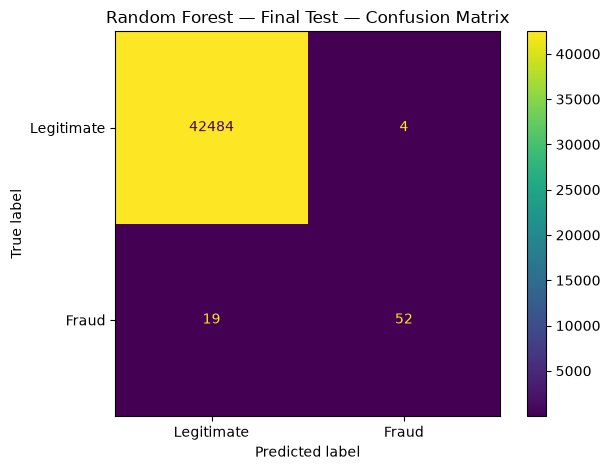


Final test metrics:


,Model,Precision,Recall,F1-score,Average Precision
0,Random Forest — Final Test,0.9286,0.7324,0.8189,0.7899


In [29]:
test_results = evaluate_model(
    best_model,
    X_test,
    y_test,
    f"{best_model_name} — Final Test"
)

print("\nFinal test metrics:")
display(pd.DataFrame([test_results]).round(4))

In [30]:
os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/fraud_detection_model.joblib")

joblib.dump(
    X.columns.tolist(),
    "models/feature_names.joblib"
)

print("Model saved to models/fraud_detection_model.joblib")
print("Feature names saved to models/feature_names.joblib")

Model saved to models/fraud_detection_model.joblib
Feature names saved to models/feature_names.joblib


In [31]:
os.makedirs("results", exist_ok=True)

comparison.to_csv("results/model_comparison.csv", index=False)

pd.DataFrame([test_results]).to_csv(
    "results/final_test_results.csv",
    index=False
)

print("Saved:")
print("- results/model_comparison.csv")
print("- results/final_test_results.csv")

Saved:
- results/model_comparison.csv
- results/final_test_results.csv
